# Model Analysis

This notebook trains the network, evaluates it on the test set and compares it with two simple baselines (logistic regression and random forest).


In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             precision_score, recall_score, roc_auc_score)

# Make the modules in src/ importable from the notebooks/ folder
sys.path.append(str(Path.cwd().parent / "src"))

from config import INPUT_SIZE, DROPOUT, DEVICE
from data import load_data, preprocessing
from model import HDD

# Fixed seeds so the results are reproducible
torch.manual_seed(42)
np.random.seed(42)

/Users/mr/Code/AI/heart-disease-diagnosis/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Data
Loading and preprocessing the data.

In [2]:
df = load_data()
(train_loader, val_loader, test_loader), scaler = preprocessing(df)

# 2. Training
`fit` uses early stopping and restores the weight of the best epoch.

In [3]:
model = HDD(input_size=INPUT_SIZE, dropout=DROPOUT)
model = model.fit(train_loader, val_loader)

Training, using the Device: mps
Epoch   0 | train 0.6142 | val 0.5749
Epoch   1 | train 0.5756 | val 0.5584
Epoch   2 | train 0.5682 | val 0.5554
Epoch   3 | train 0.5607 | val 0.5512
Epoch   4 | train 0.5570 | val 0.5498
Epoch   5 | train 0.5551 | val 0.5509
Epoch   6 | train 0.5535 | val 0.5515
Epoch   7 | train 0.5532 | val 0.5492
Epoch   8 | train 0.5520 | val 0.5480
Epoch   9 | train 0.5523 | val 0.5499
Epoch  10 | train 0.5511 | val 0.5474
Epoch  11 | train 0.5513 | val 0.5464
Epoch  12 | train 0.5501 | val 0.5467
Epoch  13 | train 0.5496 | val 0.5474
Epoch  14 | train 0.5501 | val 0.5461
Epoch  15 | train 0.5497 | val 0.5453
Epoch  16 | train 0.5486 | val 0.5467
Epoch  17 | train 0.5472 | val 0.5456
Epoch  18 | train 0.5497 | val 0.5455
Epoch  19 | train 0.5481 | val 0.5458
Epoch  20 | train 0.5486 | val 0.5467
Epoch  21 | train 0.5478 | val 0.5455
Epoch  22 | train 0.5473 | val 0.5456
Epoch  23 | train 0.5475 | val 0.5450
Epoch  24 | train 0.5477 | val 0.5453
Epoch  25 | train 

# 3. Evaluation on the test set
Accuracy, AUC and per-class report from `evaluate`

In [4]:
model.evaluate(test_loader)

Test Accuracy: 0.7322
Test AUC: 0.795
              precision    recall  f1-score   support

      gesund       0.72      0.76      0.74      5253
       krank       0.74      0.71      0.73      5247

    accuracy                           0.73     10500
   macro avg       0.73      0.73      0.73     10500
weighted avg       0.73      0.73      0.73     10500



# 4. Comparison with baselines
Compare with Logistic Regression and Random Forest Classifier as a baseline. All models are scored on the same test set.
The network should at least match the simple models.

In [ ]:
@torch.no_grad()
def predict_probs(model, loader):
    """Return (probabilities, true labels) for a DataLoader as NumPy arrays."""
    model.eval()
    probs, targets = [], []
    for xb, yb in loader:
        probs.append(torch.sigmoid(model(xb.to(DEVICE))).detach().cpu())
        targets.append(yb)
    return torch.cat(probs).numpy().ravel(), torch.cat(targets).numpy().ravel()

test_probs, test_targets = predict_probs(model, test_loader)

X_train = train_loader.dataset.tensors[0]
y_train = train_loader.dataset.tensors[1]
X_test = test_loader.dataset.tensors[0]

log_reg = LogisticRegression(class_weight="balanced", max_iter=1000).fit(X_train, y_train)
forest = RandomForestClassifier(class_weight="balanced", n_estimators=200, random_state=42).fit(X_train, y_train)

scores = {
    "Neural network": test_probs,
    "Logistic regression": log_reg.predict_proba(X_test)[:, 1],
    "Random forest": forest.predict_proba(X_test)[:, 1],
}

results = pd.Series({name: roc_auc_score(test_targets, p) for name, p in scores.items()}, name="Test AUC")
results.round(3).to_frame()

/Users/mr/Code/AI/heart-disease-diagnosis/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/mr/Code/AI/heart-disease-diagnosis/.venv/lib/python3.13/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,Test AUC
Neural network,0.795
Logistic regression,0.773
Random forest,0.772


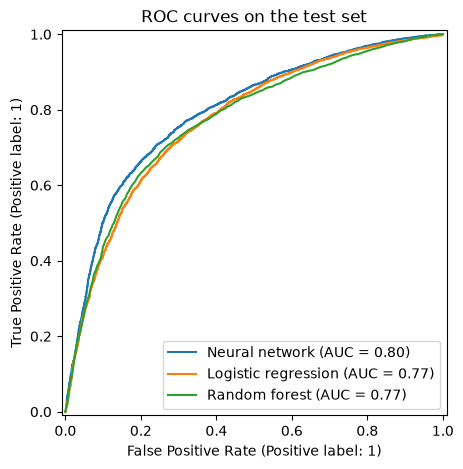

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in scores.items():
    RocCurveDisplay.from_predictions(test_targets, p, name=name, ax=ax)
ax.set_title("ROC curves on the test set")
ax.legend()
plt.show()

# 5. Confusion matrix
Rows are the classes, columns are the predictions.

<function matplotlib.pyplot.show(close=None, block=None)>

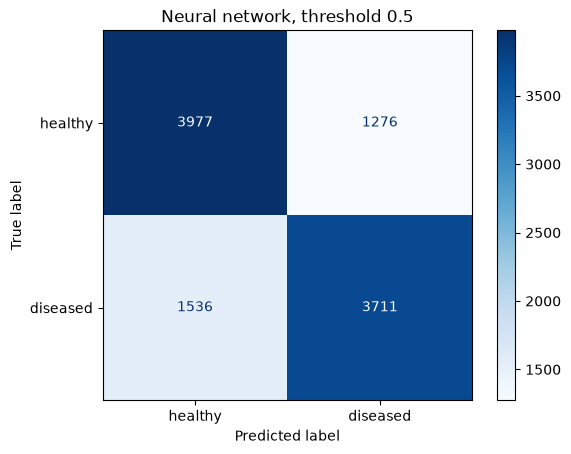

In [8]:
ConfusionMatrixDisplay.from_predictions(test_targets, test_probs >= 0.5, display_labels=["healthy", "diseased"], cmap="Blues")

plt.title("Neural network, threshold 0.5")
plt.show